,ID,Color,Testimony,Cluster
0,﻿1,NaN,On uneven paths the heel feels wobbly side‑to‑...,0
1,2,0x000000,"The feverish feeling eased, but I’m now breath...",2
2,3,0x000000,"While working in the garden, I touched a metal...",0
3,4,NaN,A short sprint brought on a twinge in the midd...,1
4,5,0x000000,I accidentally left my hand on a hot mug for a...,0


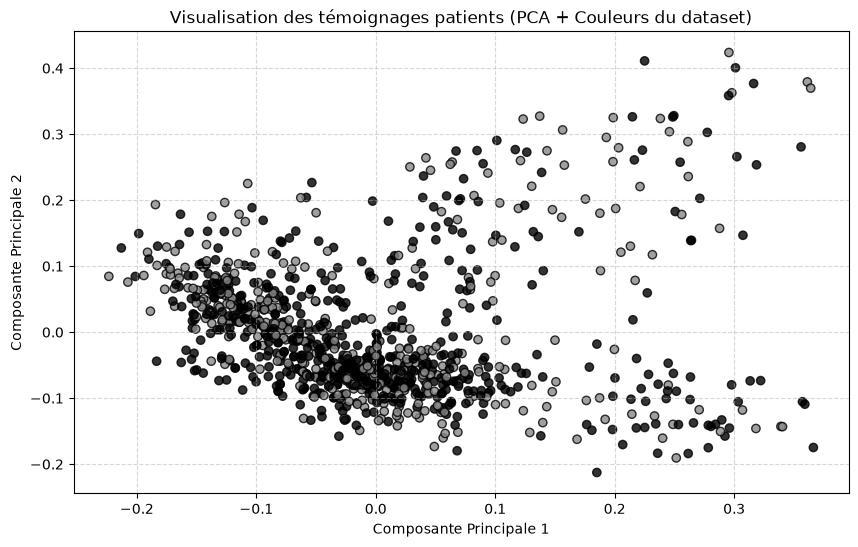

Score de Silhouette (K=4) : 0.0104

--- Mots-clés du Cluster 0 ---
itchy, skin, hot, feels, red

--- Mots-clés du Cluster 1 ---
pain, ache, makes, sharp, deep

--- Mots-clés du Cluster 2 ---
cough, throat, cold, felt, mild

--- Mots-clés du Cluster 3 ---
feel, ve, doctor, pressure, feeling


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# 1. Charger le fichier proprement en gérant les lignes à 2 ou 3 colonnes
rows = []
with open('../data/Student_Dataset.csv', 'r', encoding='utf-8') as f:
    for line in f:
        # Séparer par la virgule en gérant les guillemets
        parts = line.strip().split(',', 2)
        if len(parts) == 3:
            # ci 3 éléments : ID, Color, Testimony
            row_id, color, testimony = parts
            # ci le 2ème élément est une couleur (ex: 0x000000)
            if color.startswith('0x'):
                rows.append({'ID': row_id, 'Color': color, 'Testimony': testimony.strip('"')})
            else:
                # ci c'était du texte sans couleur
                rows.append({'ID': row_id, 'Color': None, 'Testimony': f"{color} {testimony}".strip('"')})
        elif len(parts) == 2:
            # ci 2 éléments : ID, Testimony
            row_id, testimony = parts
            rows.append({'ID': row_id, 'Color': None, 'Testimony': testimony.strip('"')})

df = pd.DataFrame(rows)

# 2. Nettoyer les lignes sans témoignage
df_clean = df.dropna(subset=['Testimony']).copy()

# 3. Préparer les couleurs pour Matplotlib
colors_formatted = df_clean['Color'].fillna('#888888').astype(str).str.replace('0x', '#')

# 4. Vectorisation TF-IDF (NLP)
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(df_clean['Testimony'])

# 5. Clustering K-Means (4 groupes)
kmeans = KMeans(n_clusters=4, random_state=42)
df_clean['Cluster'] = kmeans.fit_predict(X)

# Afficher un aperçu propre du DataFrame
display(df_clean.head())

# 6. Réduction 2D avec PCA & Visualisation Graphique
pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(X.toarray())

plt.figure(figsize=(10, 6))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], c=colors_formatted, alpha=0.8, edgecolors='k')
plt.title("Visualisation des témoignages patients (PCA + Couleurs du dataset)")
plt.xlabel("Composante Principale 1")
plt.ylabel("Composante Principale 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 7. Évaluation avec le Silhouette Score
score = silhouette_score(X, df_clean['Cluster'])
print(f"Score de Silhouette (K=4) : {score:.4f}")

# 8. Mots-clés par Cluster (pour expliquer les pathologies)
words = np.array(vectorizer.get_feature_names_out())
for cluster_id in range(4):
    cluster_indices = np.where(df_clean['Cluster'] == cluster_id)[0]
    mean_tfidf = X[cluster_indices].mean(axis=0).A1
    top_words = words[mean_tfidf.argsort()[::-1][:5]]
    print(f"\n--- Mots-clés du Cluster {cluster_id} ---")
    print(", ".join(top_words))